In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import numpy as np
import csv
import re
plt.rcParams['text.usetex'] = False
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['mathtext.rm'] = 'sans'
plt.rcParams['axes.titlepad'] = 20
cmap = mpl.colormaps['Greens']

# Analysis code for the Excel file

This code helps to do some nice plots :)

1. It loads in the Excel and reads the rows.
2. I defined the mapping between the wells and the amino acid parents, it uses these to read the 1 h - 4 h timeseries.
3. I am plotting the inclusions with t = 0 h autofluorescence correction, however, I am plotting the negative controls separately and without subtracting these from the real data to see how much the real data is above the negative controls and make sure the negative controls are low.
4. Three different plot types are important:
   - [X] total fluorescence comparison plot across all (green plot)
   - [X] fluorescence comparison plots per amino acid parent
   - [X] total fluorescence comparison across all, now with coloration depending on parent
5. The colors used you can redefine below. :) Give a strong top color, the code then makes a colormap fading towards less coloration and sorts

In [7]:
item = 2

test = {"A5": 2, "A6": 115}

test = {test[i] - item for i in test}

test

{0, 113}

In [8]:
def read_rows(rows):

    positive = {"+canonical": rows[1][1]}
    negatives = {"-F": rows[2][1], "-H": rows[3][1], "-I": rows[4][1], "-W": rows[5][1], "-Y": rows[6][1]}
    ile = {"A5": rows[1][5], "A6": rows[1][6], "B4": rows[2][4], "C2": rows[3][2], "F8": rows[6][8], "G3": rows[7][3], "G9": rows[7][9], "G10": rows[7][10], "I1": rows[9][1]}
    his = {"A11": rows[1][11], "C8": rows[3][8], "E6": rows[5][6], "G6": rows[7][6]}
    phe = {"A3": rows[1][3], "A9": rows[1][9], "A10": rows[1][10], "D2": rows[4][2], "G2": rows[7][2], "H3": rows[8][3], "H8": rows[8][8]}
    trp = {"B6": rows[2][6], "C6": rows[3][6], "C9": rows[3][9], "D9": rows[4][9], "D11": rows[4][11], "E4": rows[5][4], "F4": rows[6][4], "H10": rows[8][10]}
    tyr = {"A2": rows[1][2], "B5": rows[2][5], "C10": rows[3][10], "D6": rows[4][6], "F10": rows[6][10], "H2": rows[8][2]}

    merged = positive | negatives | ile | his | phe | trp | tyr

    return positive, negatives, ile, his, phe, trp, tyr, merged


def read_with_controls(rows):

    positive = {"+all 20": rows[1][1]}
    negatives = {"-F": rows[2][1], "-H": rows[3][1], "-I": rows[4][1], "-W": rows[5][1], "-Y": rows[6][1]}
    
    ile = {"A5": rows[1][5], "A6": rows[1][6], "B4": rows[2][4], "C2": rows[3][2], "F8": rows[6][8], "G3": rows[7][3], "G9": rows[7][9], "G10": rows[7][10], "I1": rows[9][1]}
    his = {"A11": rows[1][11], "C8": rows[3][8], "E6": rows[5][6], "G6": rows[7][6]}
    phe = {"A3": rows[1][3], "A9": rows[1][9], "A10": rows[1][10], "D2": rows[4][2], "G2": rows[7][2], "H3": rows[8][3], "H8": rows[8][8]}
    trp = {"B6": rows[2][6], "C6": rows[3][6], "C9": rows[3][9], "D9": rows[4][9], "D11": rows[4][11], "E4": rows[5][4], "F4": rows[6][4], "H10": rows[8][10]}
    tyr = {"A2": rows[1][2], "B5": rows[2][5], "C10": rows[3][10], "D6": rows[4][6], "F10": rows[6][10], "H2": rows[8][2]}

    # correct
    ile = {ile[i] - negatives["-I"] for i in ile}
    his = {his[i] - negatives["-H"] for i in his}
    trp = {trp[i] - negatives["-W"] for i in trp}
    phe = {phe[i] - negatives["-F"] for i in phe}
    tyr = {tyr[i] - negatives["-Y"] for i in tyr}
    
    merged = positive | ile | his | phe | trp | tyr

    return positive, ile, his, phe, trp, tyr, merged
    

In [10]:
ts = [1, 2, 3, 4]

df = pd.DataFrame()

with open("data/run-1/run-1-t-0.csv", newline="\n") as file:
    fluorescence_reader = csv.reader(file, delimiter=";")
    rows = [row for row in fluorescence_reader]


positive_0, negatives_0, ile_0, his_0, phe_0, trp_0, tyr_0, merged_0 = read_rows(rows)

alle = [key for d in [positive_0, negatives_0, ile_0, his_0, phe_0, trp_0, tyr_0] for key in d]

for well in alle: 
    df.loc[0, well] = 0 #merged_0[well]


for time in ts:

    with open(f"data/run-1/run-1-t-{time}.csv", newline="\n") as file:
        fluorescence_reader = csv.reader(file, delimiter=";")
        rows = [row for row in fluorescence_reader]

        positive, negatives, ile, his, phe, trp, tyr, merged = read_rows(rows)

        for well in alle: 
           df.loc[time, well] = int(merged[well])

df = df.sort_values(by=4, axis=1, ascending=False)

In [11]:
df 

,+canonical,A2,D2,F4,G6,C6,A3,H10,E4,A6,...,C8,G2,F10,B5,D6,-Y,-H,A5,A10,H3
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1283.0,654.0,248.0,546.0,1038.0,253.0,2529.0,167.0,725.0,927.0,...,52.0,38.0,2.0,23.0,6.0,24.0,34.0,0.0,0.0,0.0
2,5141.0,2846.0,1643.0,1823.0,2053.0,1218.0,2844.0,913.0,1452.0,1582.0,...,130.0,94.0,43.0,79.0,67.0,76.0,70.0,0.0,0.0,0.0
3,8817.0,5182.0,3670.0,3335.0,3014.0,2418.0,2642.0,1996.0,2165.0,2137.0,...,174.0,158.0,116.0,150.0,129.0,135.0,125.0,47.0,23.0,22.0
4,13621.0,8466.0,6189.0,5106.0,3950.0,3765.0,3572.0,3323.0,2804.0,2777.0,...,260.0,259.0,252.0,251.0,230.0,214.0,196.0,143.0,73.0,72.0


# Total plot

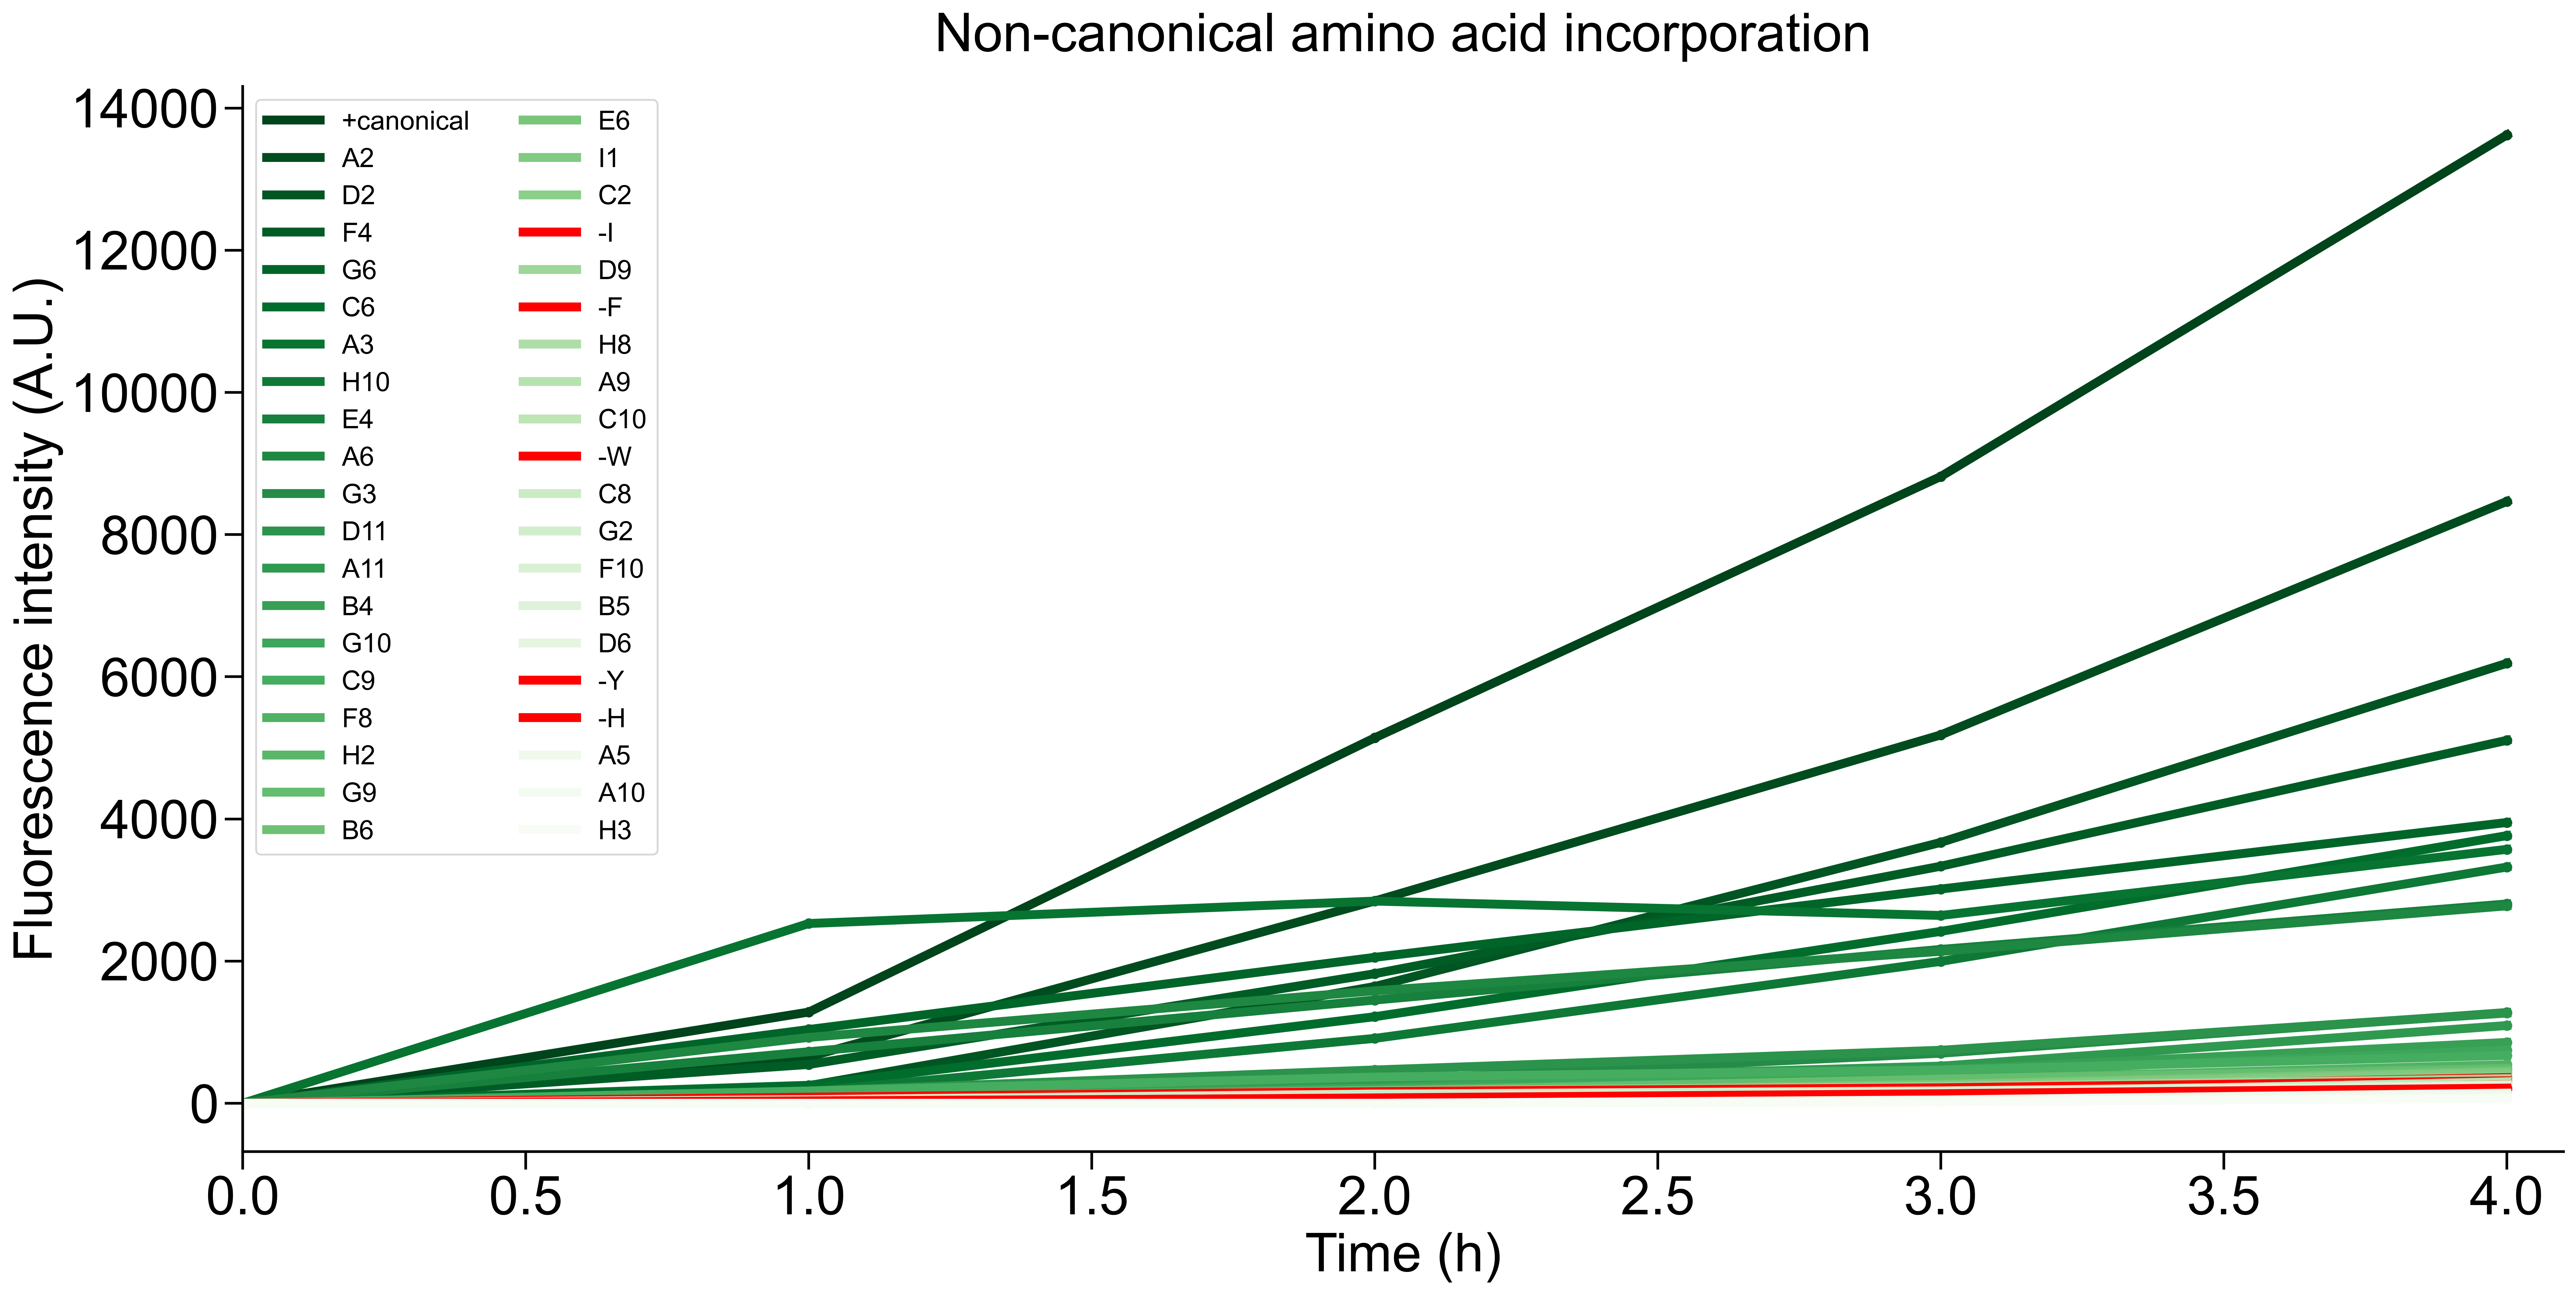

<Figure size 640x480 with 0 Axes>

In [72]:
import matplotlib.pyplot as plt
import numpy as np

fontsize = 30
linewidth = 1.5
window = 5

series_columns = [col for col in df.columns]
red_columns = ["-I", "-H", "-Y", "-W", "-F"]  # use your actual column names

greens = plt.get_cmap("Greens_r")
colors = greens(np.linspace(0, 1, len(series_columns)))

fig, ax = plt.subplots(figsize=(20, 10), dpi=400, layout="constrained")

for i, column in enumerate(series_columns):
    color = "red" if column in red_columns else colors[i]

    ax.plot(
        df[column],
        color=color,
        linewidth=5,
        #alpha=0.35,
        label=column,
    )

    ax.scatter(
        [0,1,2,3,4],
        df[column],
        color=color,
        s=24,
        #alpha=0.35,
        #label=column,
    )


ax.tick_params(axis="both", labelsize=fontsize, length=10, width=linewidth)
ax.spines[["left", "bottom"]].set_linewidth(linewidth)
ax.spines[["right", "top"]].set_visible(False)
ax.set_xlim(0, 4.1)
ax.set_xlabel("Time (h)", fontsize=fontsize)
ax.set_ylabel("Fluorescence intensity (A.U.)", fontsize=fontsize)
ax.set_title("Non-canonical amino acid incorporation", fontsize=fontsize)
ax.legend(fontsize=fontsize * 0.5, ncol=2)

plt.show()
plt.savefig("Non-canonical amino acid incorporation.png", dpi=1000)

# Colored plots

- Ile: #CAA328, #F5EBCC
- His: #E6C5FB
- Phe: #6BC6F1, #D5F1FF
- Trp: #196B24
- Tyr: #FBE3D6

In [15]:
ile

{'A5': '143',
 'A6': '2777',
 'B4': '856',
 'C2': '378',
 'F8': '543',
 'G3': '1277',
 'G9': '487',
 'G10': '749',
 'I1': '424'}

<class 'list'>


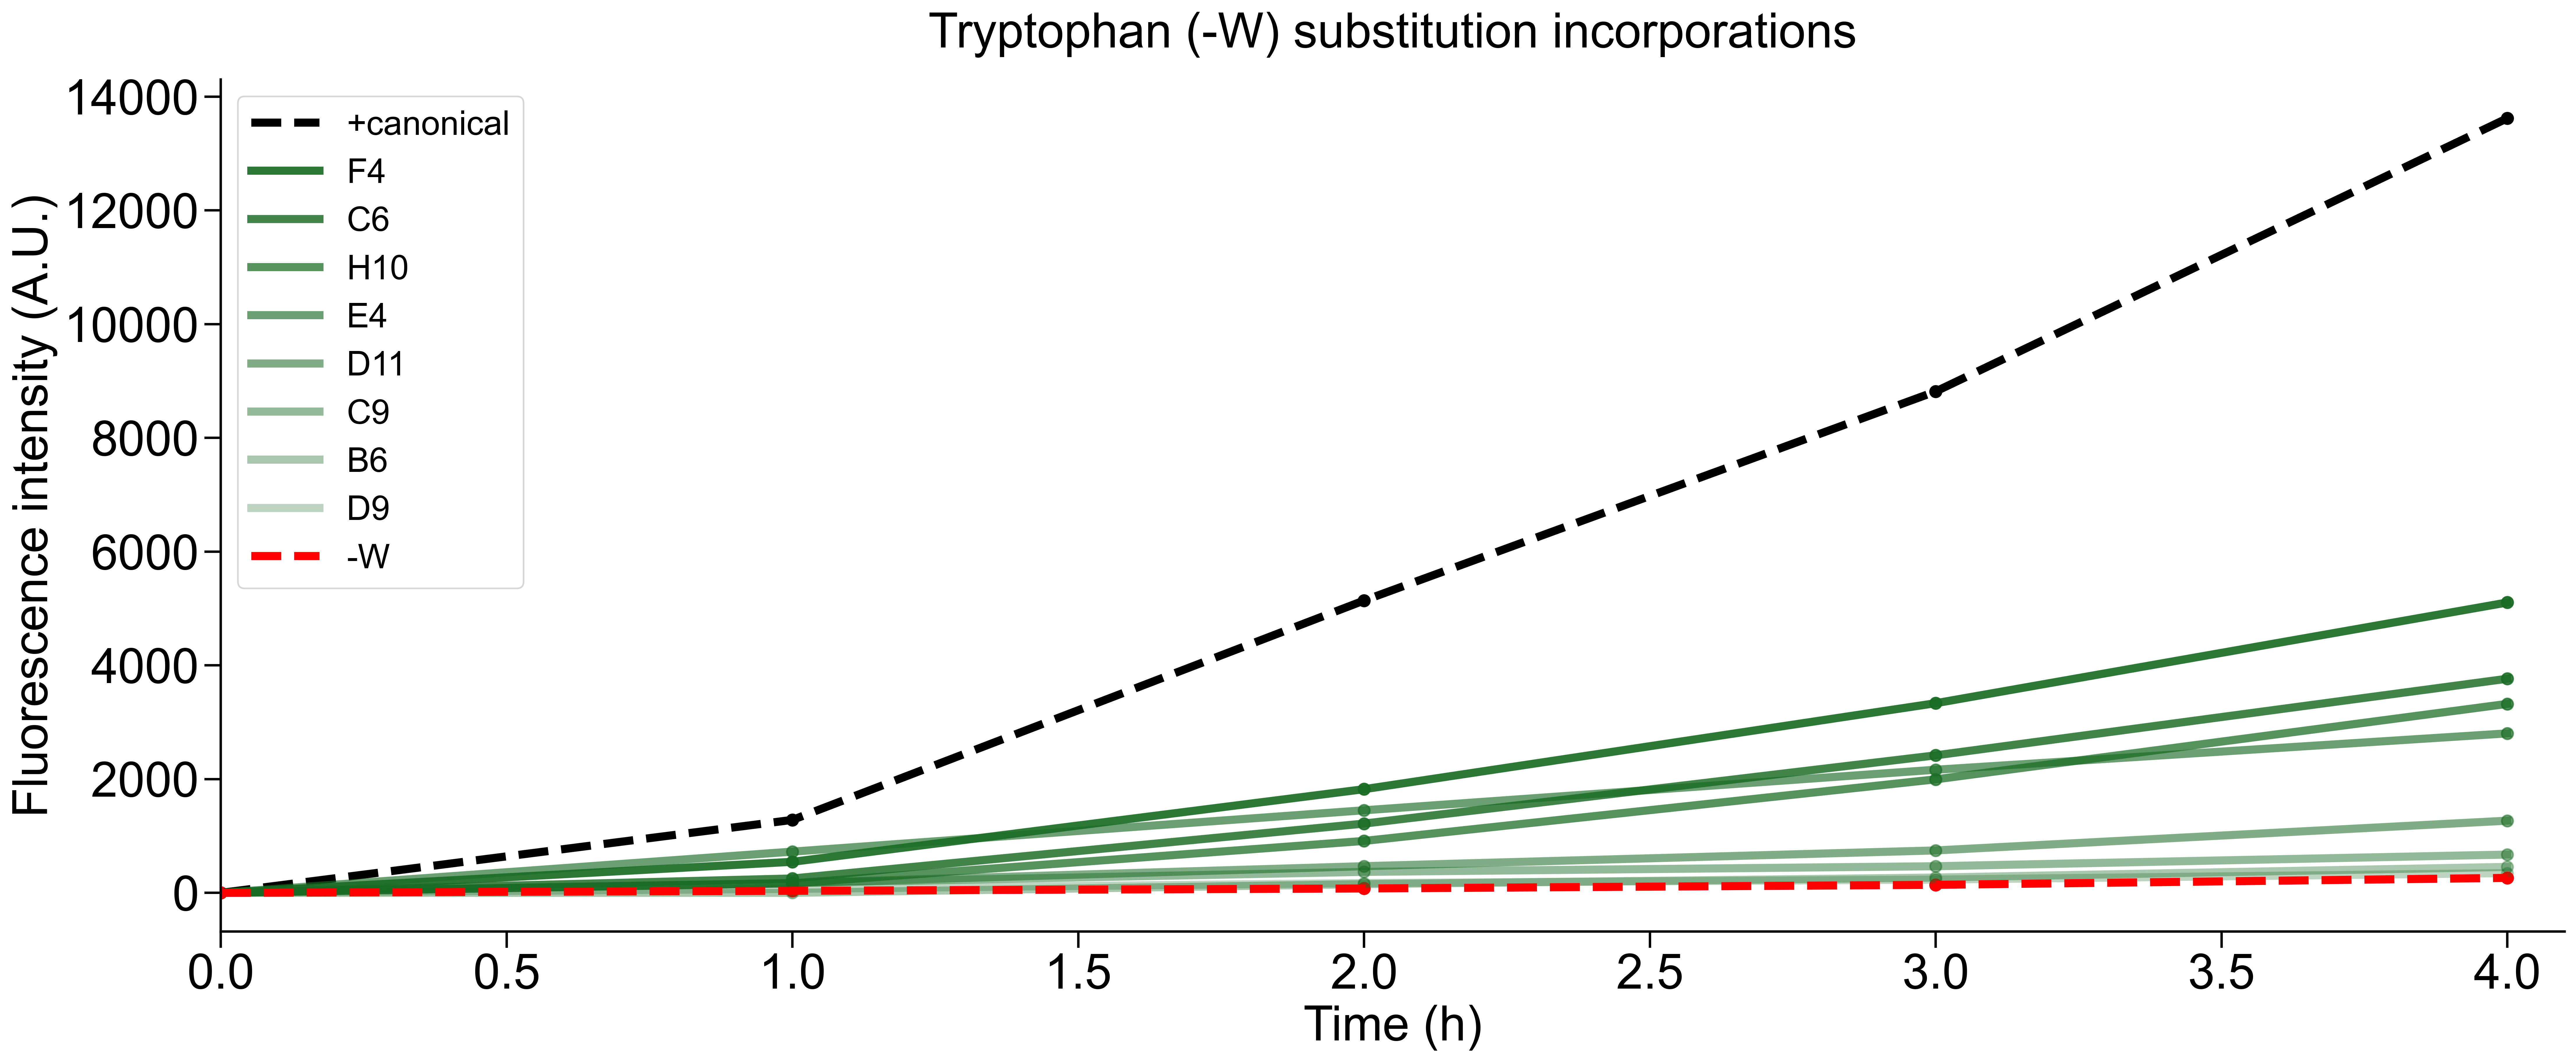

<class 'list'>


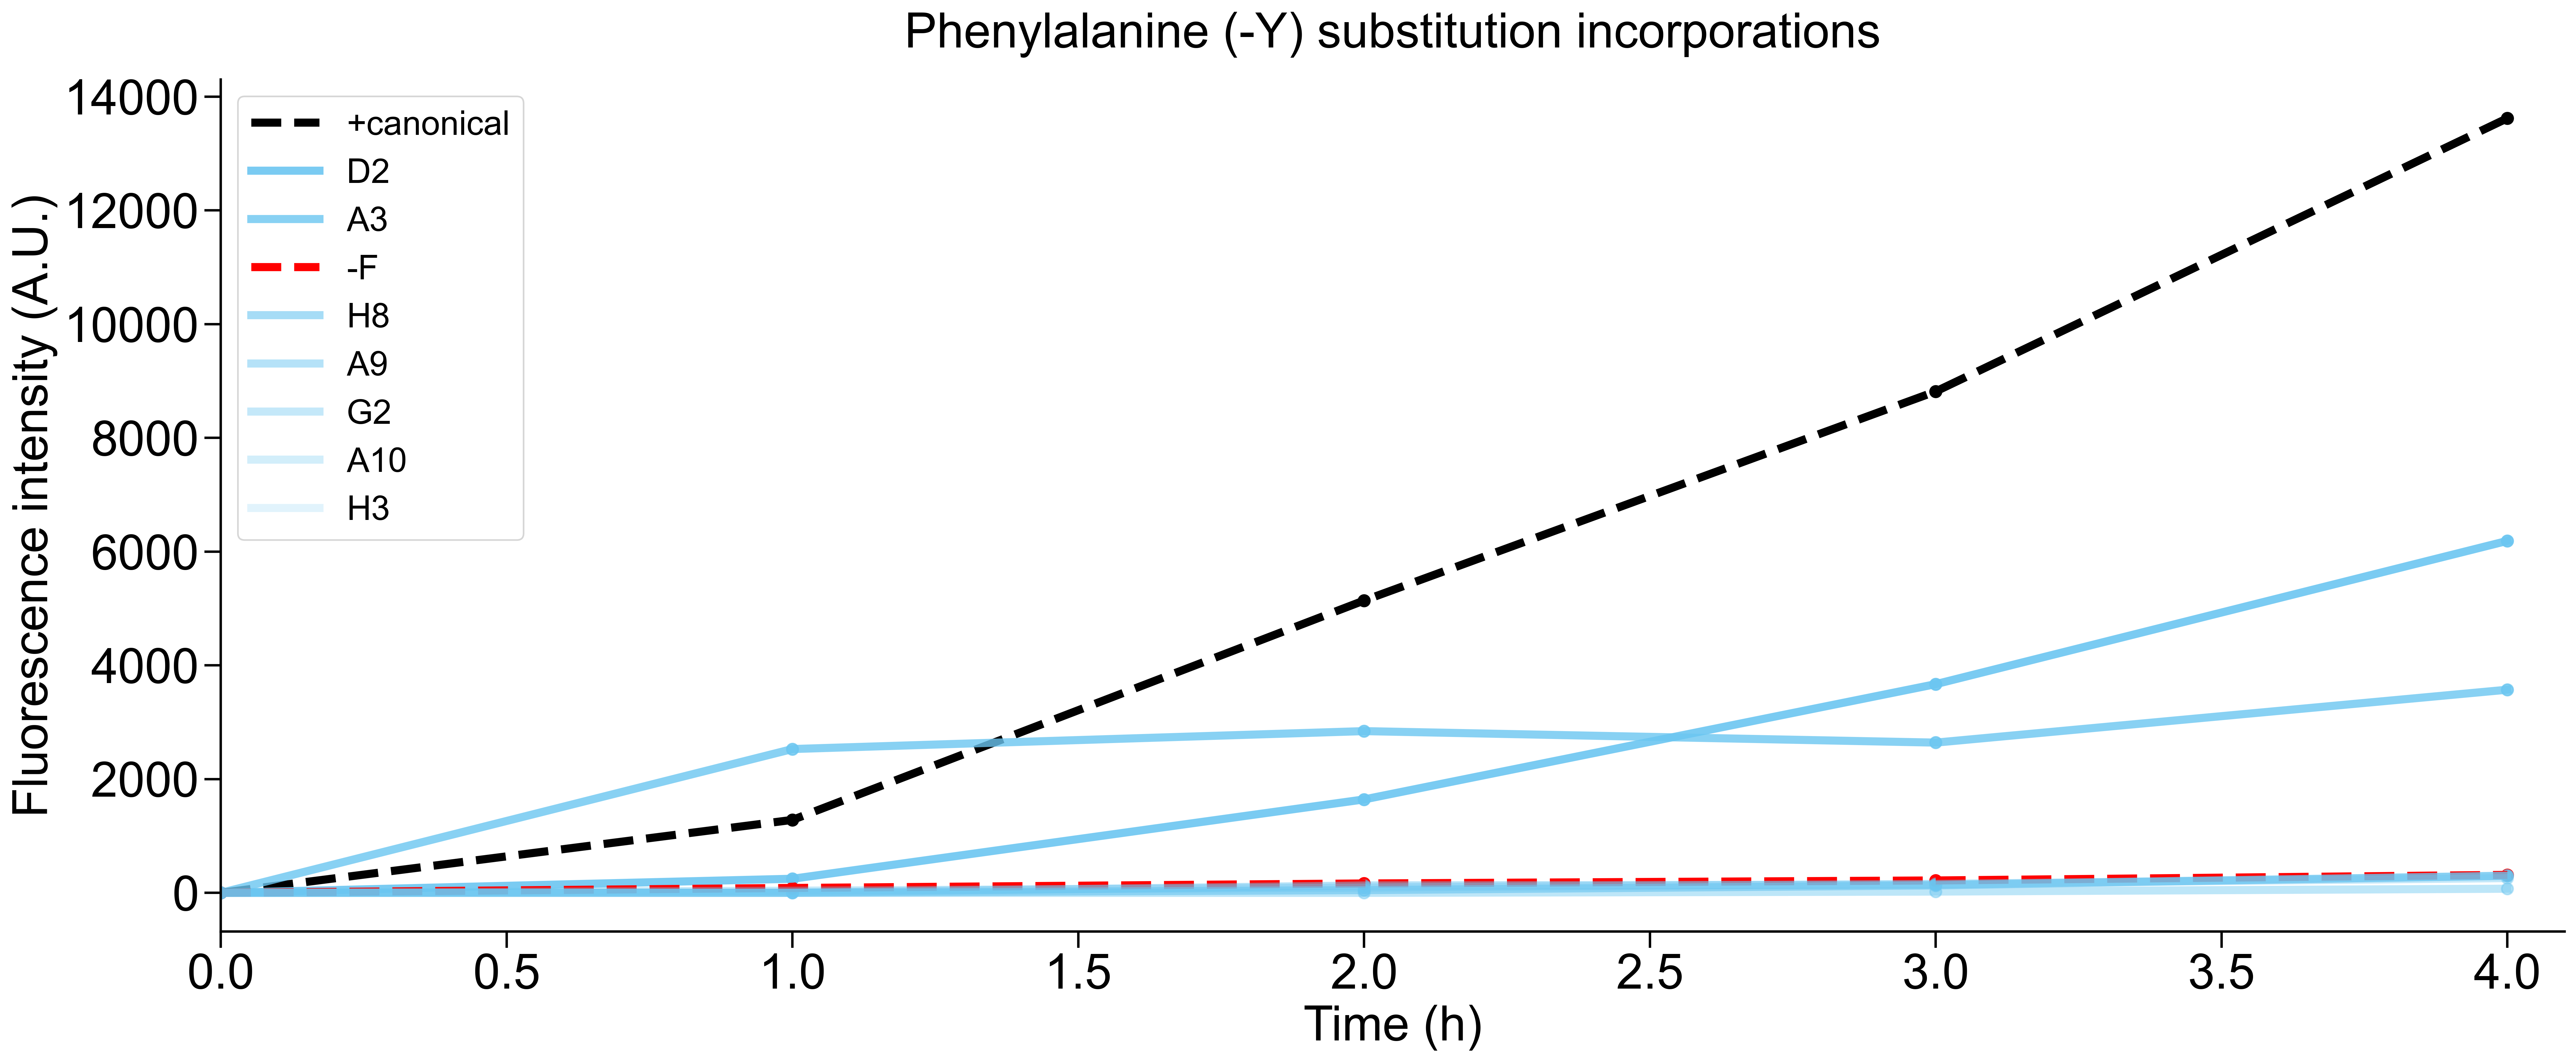

<class 'list'>


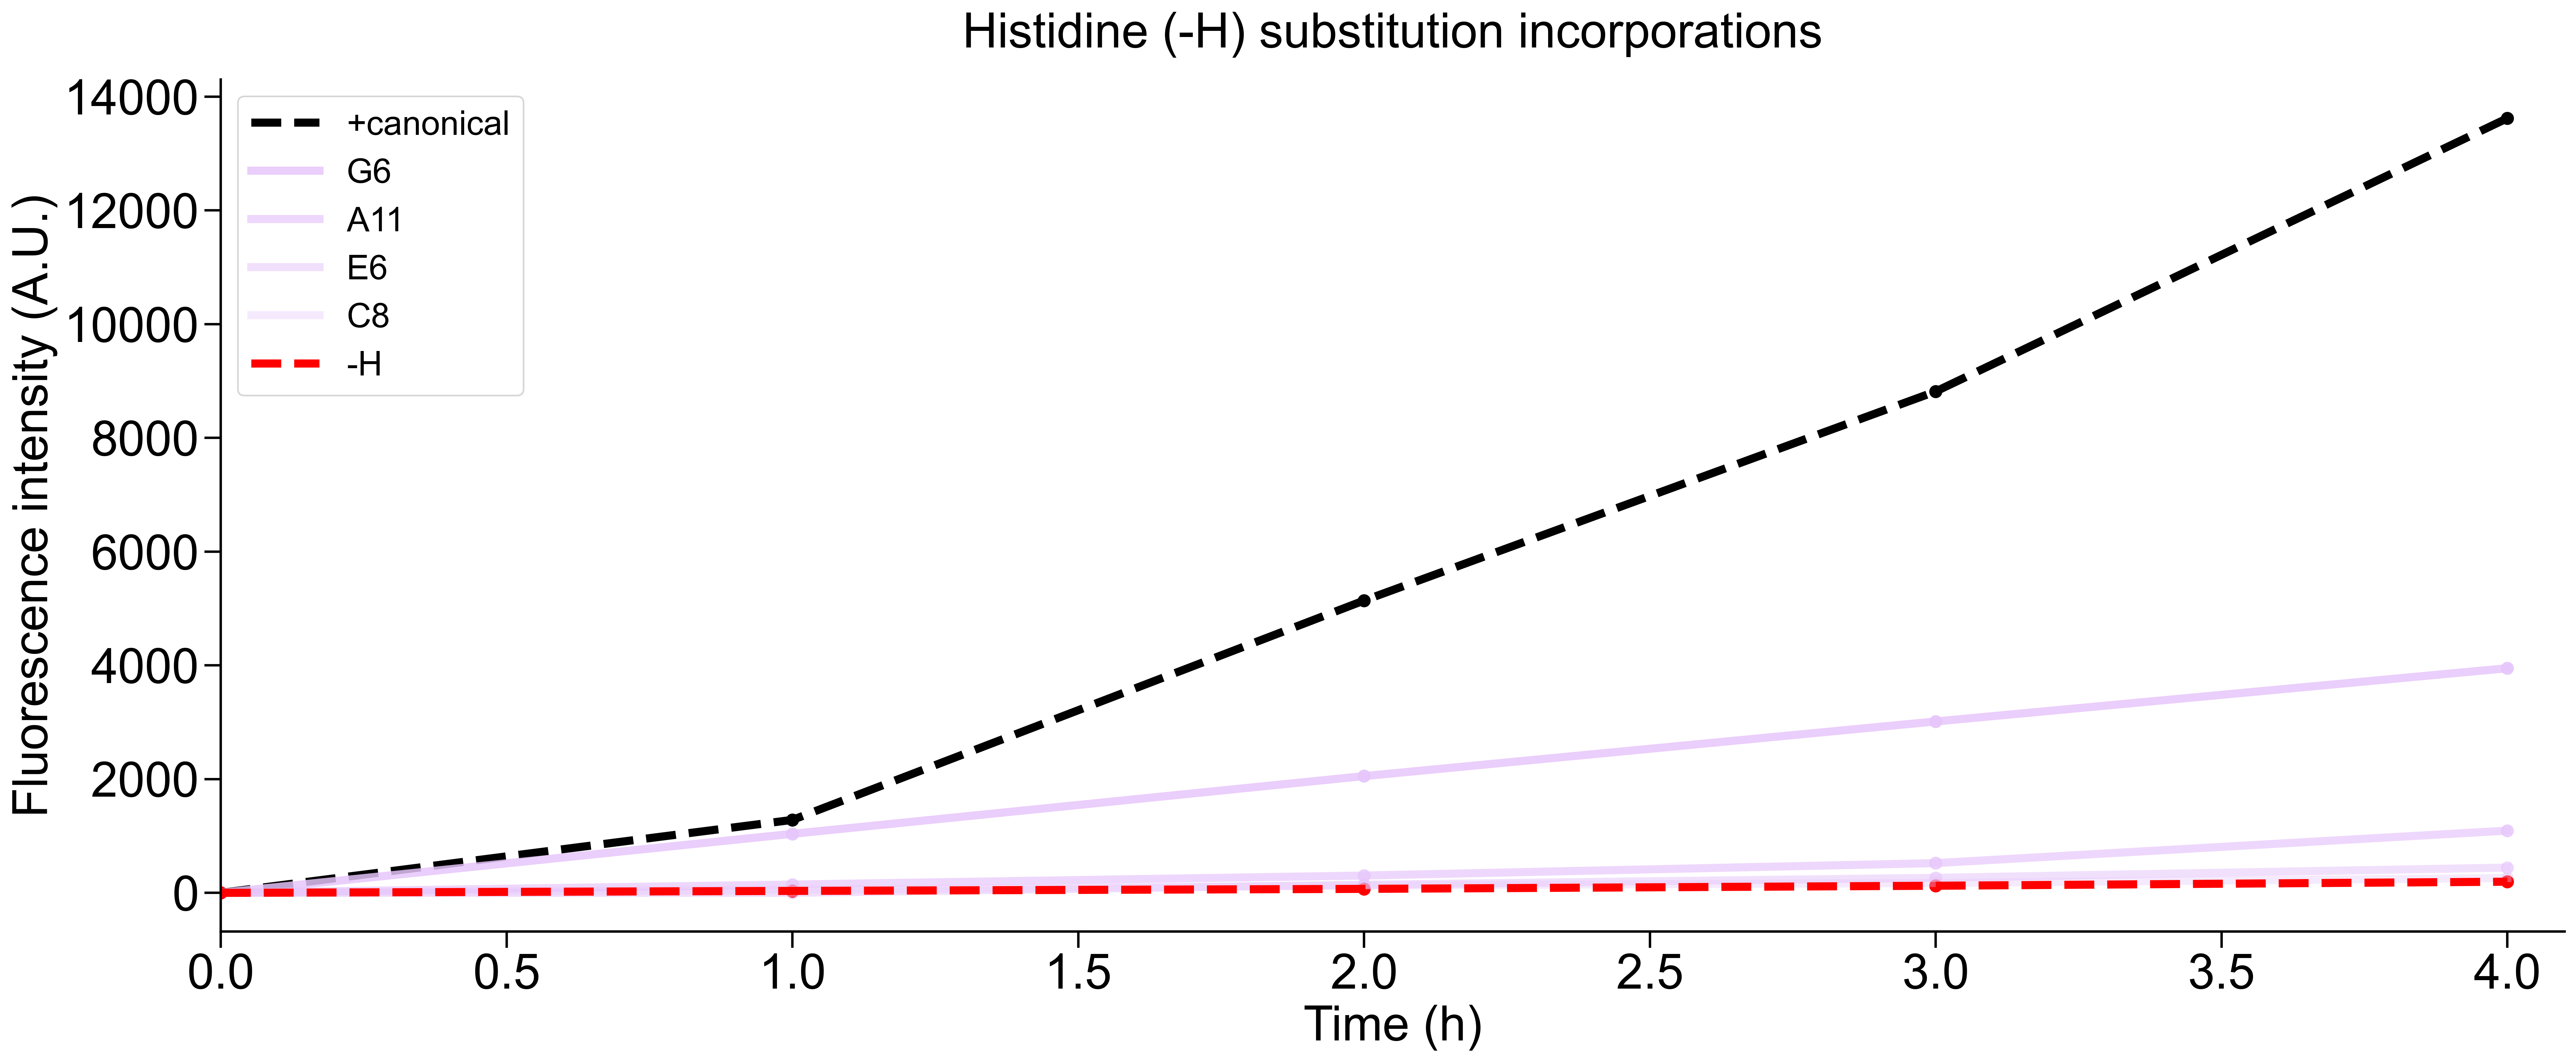

<class 'list'>


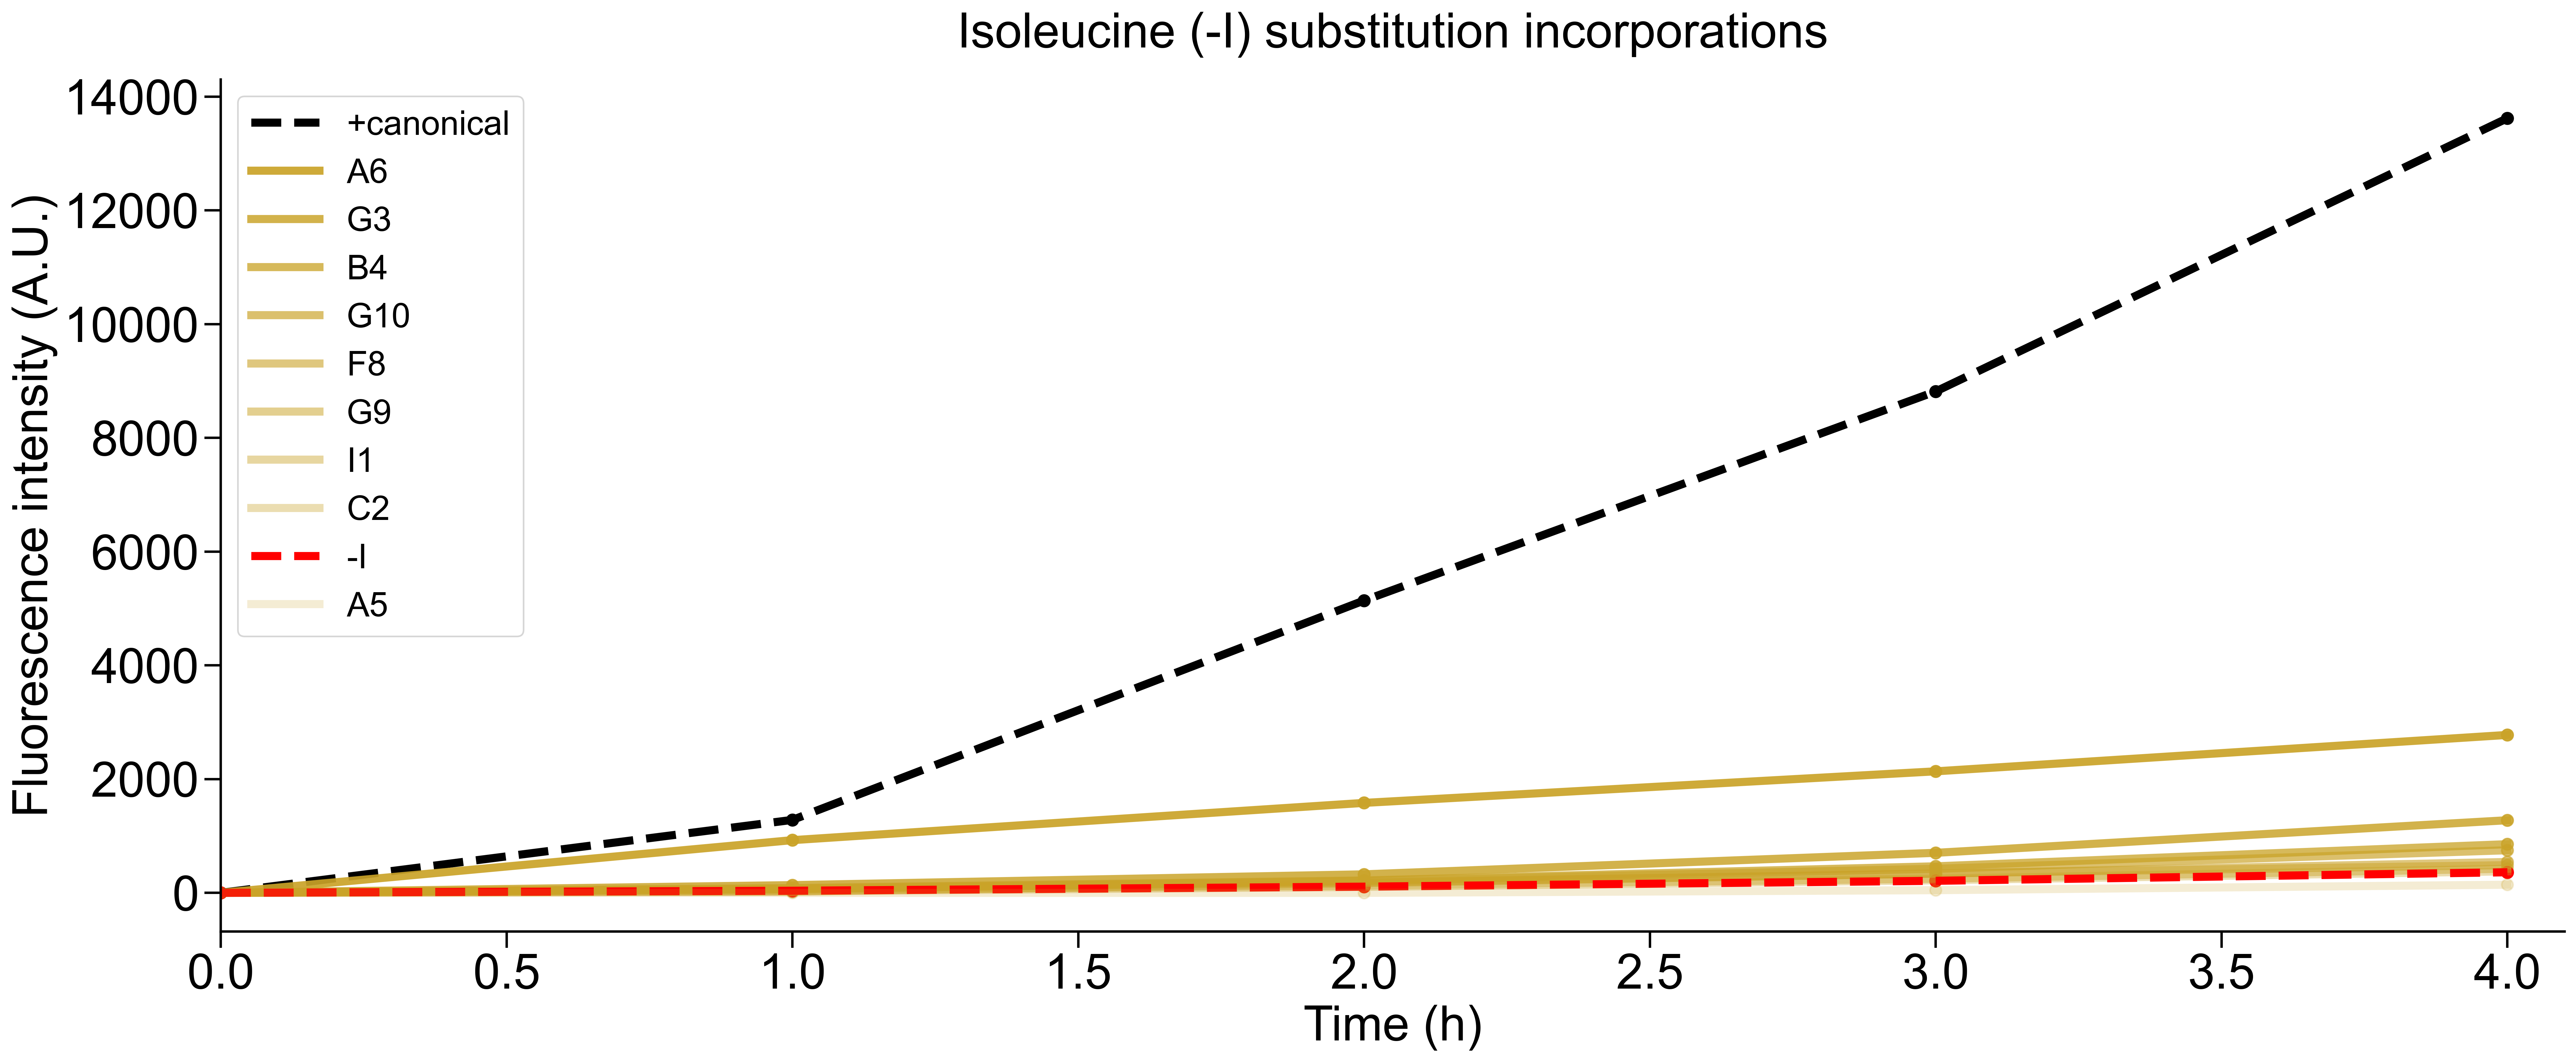

<class 'list'>


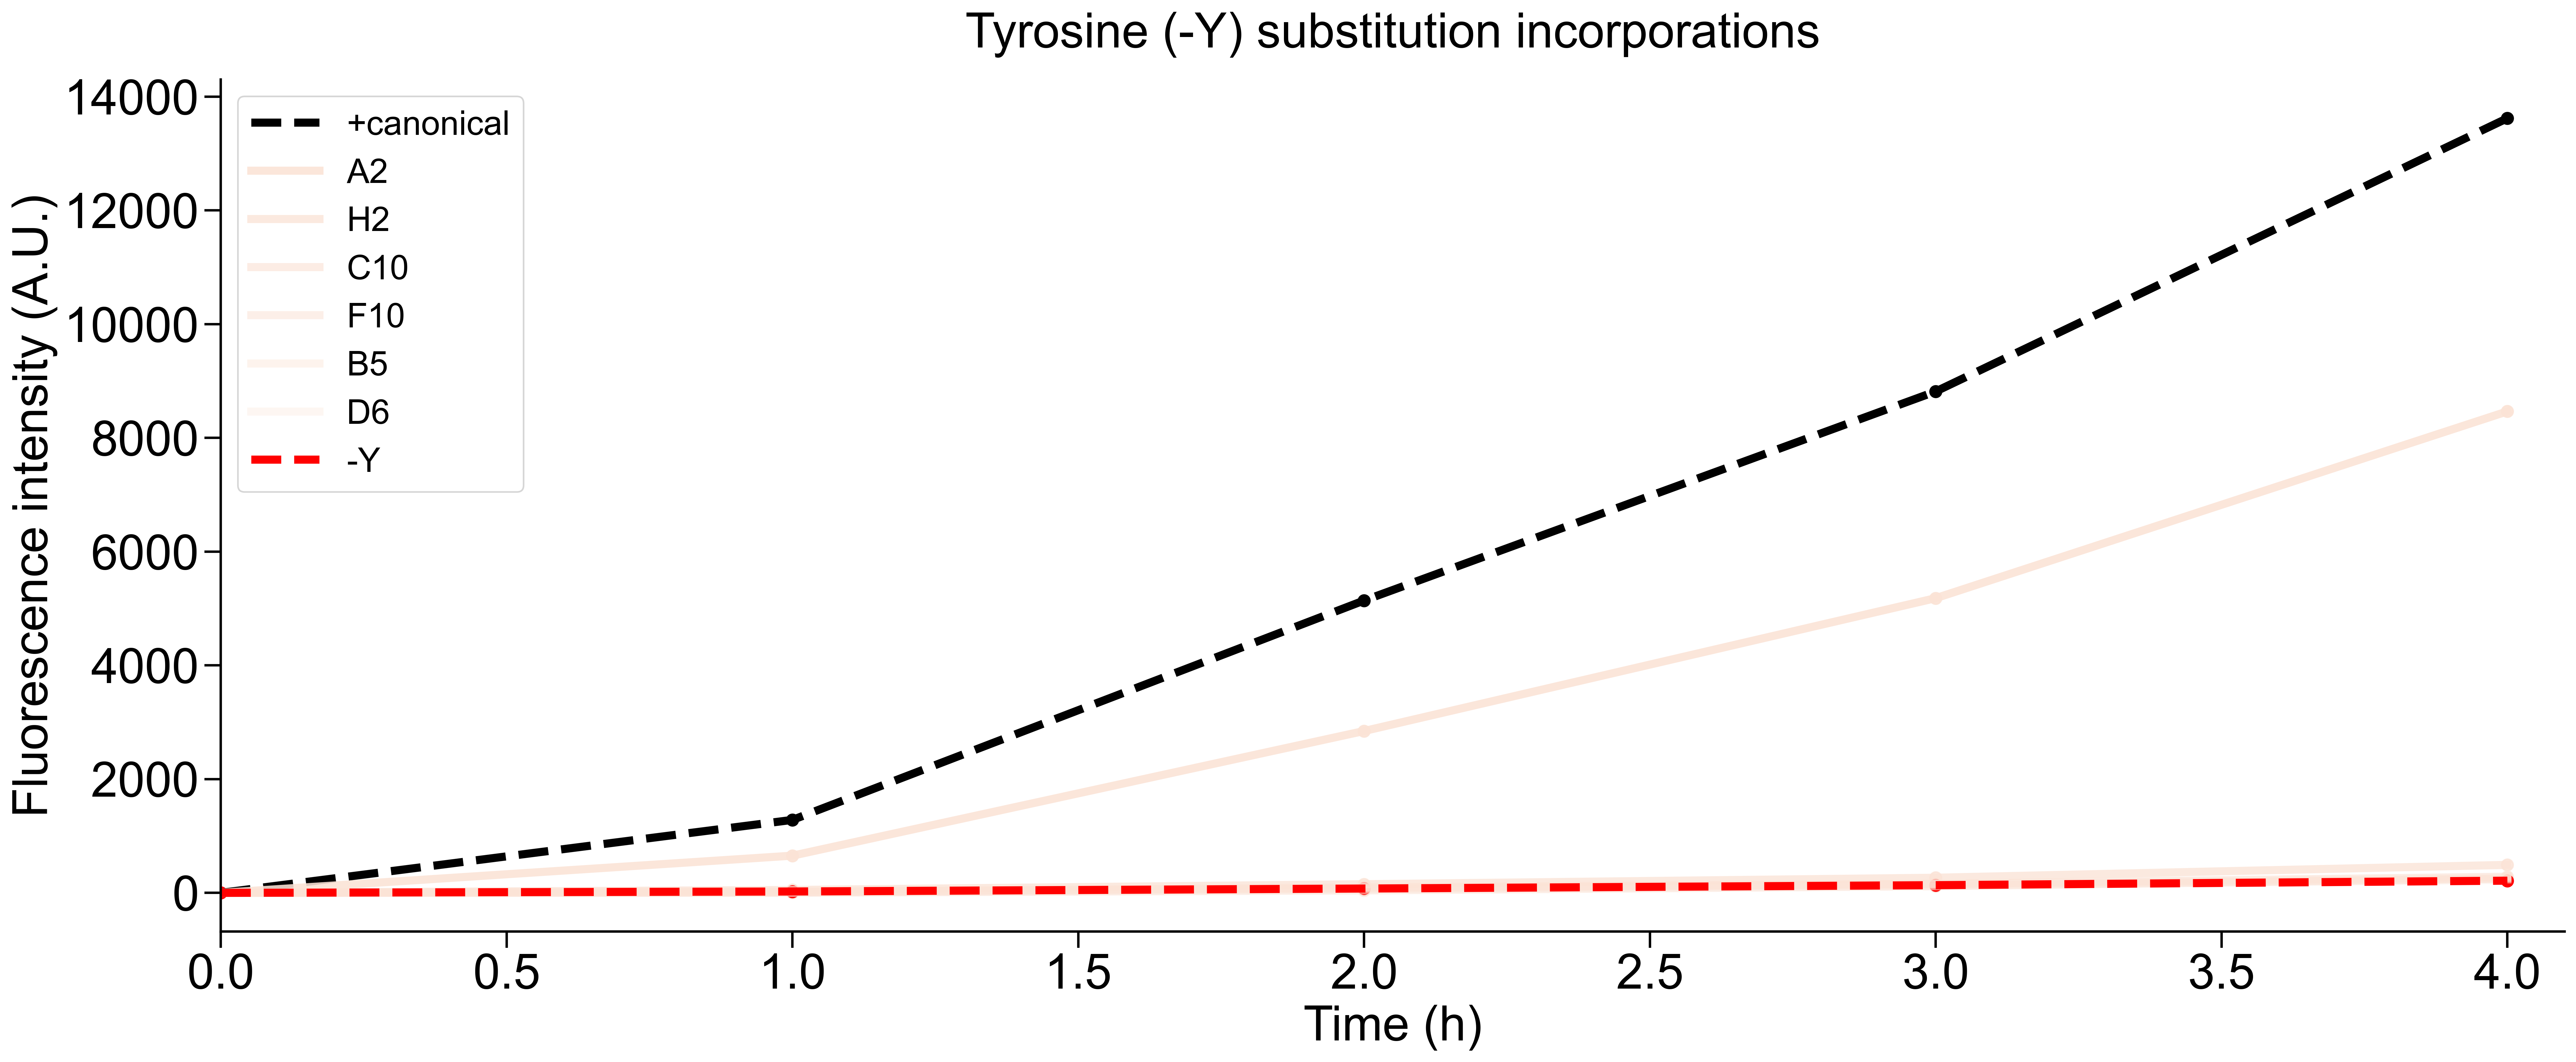

In [70]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

fontsize = 30
linewidth = 1.5
window = 5

#fig, ax = plt.subplots(figsize=(20, 5), dpi=400, layout="constrained")

amino_acids = [trp, phe, his, ile, tyr] # amino acids

amino_acids_names = ['Tryptophan (-W)', 'Phenylalanine (-Y)', 'Histidine (-H)', 'Isoleucine (-I)', 'Tyrosine (-Y)'] # amino acids

color_list = [ '#196B24', '#6BC6F1', '#E6C5FB', '#CAA328', '#FBE3D6']  # their colors

negatives = ["-W", "-F", "-H", "-I", "-Y"] 


for i, amino_acid in enumerate(amino_acids):

    fig, ax = plt.subplots(figsize=(22, 9), dpi=400, layout="constrained")

    series_columns = ["+canonical"]                              # add the positive
    red_columns = negatives[i]                                   # add the negative
    series_columns.append(negatives[i])
    series_columns.extend([col for col in amino_acid.keys()])
    
    color_aa = color_list[i]
    
    color_start = mcolors.to_rgba(color_aa, alpha=1.0)
    color_end = mcolors.to_rgba(color_aa, alpha=0.2)

    custom = mcolors.LinearSegmentedColormap.from_list("fade_out", 
                                                        [color_start, color_end],
                                                        N=256)

    colors = custom(np.linspace(0, 1, len(series_columns)))

    print(type(series_columns))

    df_aa = df[series_columns]
    df_aa = df_aa.sort_values(by=4, axis=1, ascending=False)
    df_aa

    series_columns = [col for col in df_aa.columns]    # sort now by incorporation
          
    for j, column in enumerate(series_columns):

        if column == "+canonical":

            ax.plot(
                df_aa[column],
                color='black',
                linewidth=5,
                linestyle="--",
                #alpha=0.35,
                label=column,
            )
        
            ax.scatter(
                [0,1,2,3,4],
                df_aa[column],
                color='black',
                s=50,
                #alpha=0.35,
                #label=column,
            )

        elif column in red_columns:

            ax.plot(
                df_aa[column],
                color='red',
                linewidth=5,
                linestyle="--",
                #alpha=0.35,
                label=column,
            )
        
            ax.scatter(
                [0,1,2,3,4],
                df_aa[column],
                color='red',
                s=50,
                #alpha=0.35,
                #label=column,
            )

        else:
            color = colors[j]

            amino_acid[column] = [amino_acid[column], color]
        
            ax.plot(
                df_aa[column],
                color=color,
                linewidth=5,
                #alpha=0.35,
                label=column,
            )
        
            ax.scatter(
                [0,1,2,3,4],
                df_aa[column],
                color=color,
                s=50,
                #alpha=0.35,
                #label=column,
            )


    ax.tick_params(axis="both", labelsize=fontsize, length=10, width=linewidth)
    ax.spines[["left", "bottom"]].set_linewidth(linewidth)
    ax.spines[["right", "top"]].set_visible(False)
    ax.set_xlim(0, 4.1)
    ax.set_xlabel("Time (h)", fontsize=fontsize)
    ax.set_ylabel("Fluorescence intensity (A.U.)", fontsize=fontsize)
    ax.set_title(f"{amino_acids_names[i]} substitution incorporations", fontsize=fontsize)
    ax.legend(fontsize=fontsize * 0.7, ncol=1)
    
    plt.show()
    #plt.savefig(f"{amino_acids_names[i]} substitution incorporations.png", dpi=1000)

In [38]:
df_aa = df[series_columns]
df_aa = df_aa.sort_values(by=4, axis=1, ascending=False)
df_aa

,A2,H2,C10,F10,B5,D6
0,0.0,0.0,0.0,0.0,0.0,0.0
1,654.0,51.0,13.0,2.0,23.0,6.0
2,2846.0,152.0,97.0,43.0,79.0,67.0
3,5182.0,266.0,160.0,116.0,150.0,129.0
4,8466.0,492.0,284.0,252.0,251.0,230.0


In [71]:
ile

{'A5': ['143', array([0.79215686, 0.63921569, 0.15686275, 0.2       ])],
 'A6': ['2777', array([0.79215686, 0.63921569, 0.15686275, 0.92156863])],
 'B4': ['856', array([0.79215686, 0.63921569, 0.15686275, 0.76156863])],
 'C2': ['378', array([0.79215686, 0.63921569, 0.15686275, 0.36      ])],
 'F8': ['543', array([0.79215686, 0.63921569, 0.15686275, 0.59843137])],
 'G3': ['1277', array([0.79215686, 0.63921569, 0.15686275, 0.84      ])],
 'G9': ['487', array([0.79215686, 0.63921569, 0.15686275, 0.52      ])],
 'G10': ['749', array([0.79215686, 0.63921569, 0.15686275, 0.68      ])],
 'I1': ['424', array([0.79215686, 0.63921569, 0.15686275, 0.43843137])]}

# Total plot

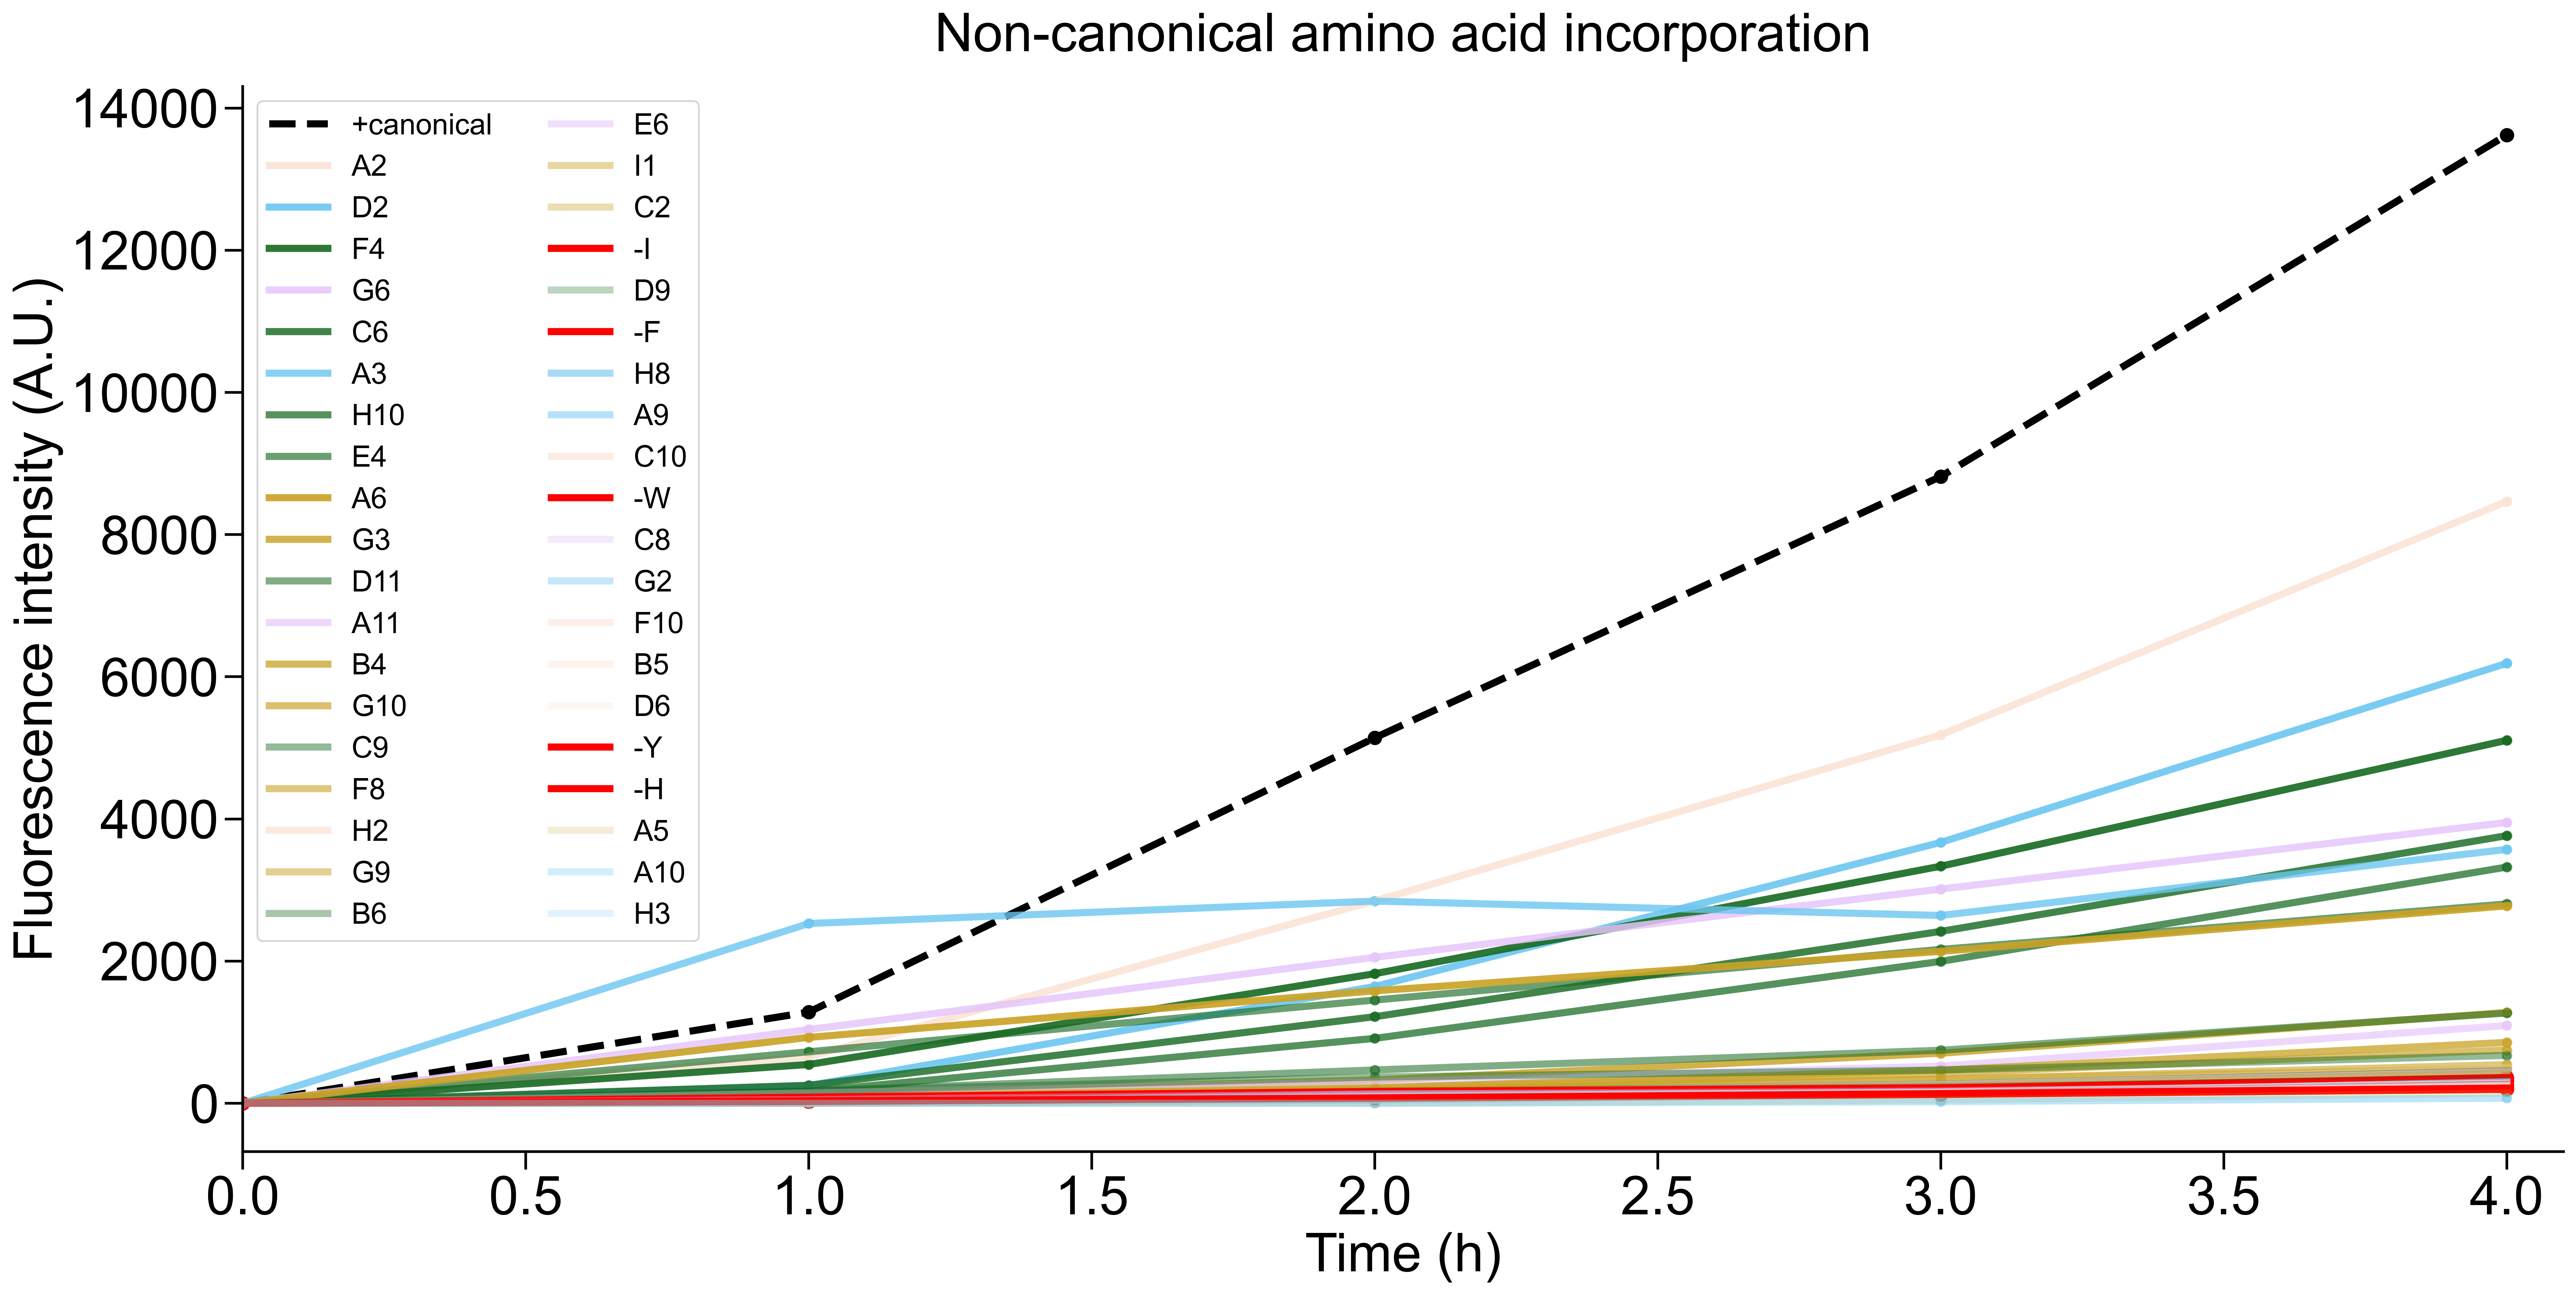

<Figure size 640x480 with 0 Axes>

In [80]:
import matplotlib.pyplot as plt
import numpy as np

fontsize = 30
linewidth = 1.5
window = 5

series_columns = [col for col in df.columns]
red_columns = ["-I", "-H", "-Y", "-W", "-F"]  # use your actual column names


fig, ax = plt.subplots(figsize=(20, 10), dpi=400, layout="constrained")

for i, column in enumerate(series_columns):

    # plot positives 
    
    if column == "+canonical":

        ax.plot(
            df[column],
            color='black',
            linewidth=4,
            linestyle="--",
            #alpha=0.35,
            label=column,
        )
    
        ax.scatter(
            [0,1,2,3,4],
            df[column],
            color='black',
            s=50,
            #alpha=0.35,
            #label=column,
        )

    # plot negatives
    
    elif column in red_columns:

        ax.plot(
            df[column],
            color='red',
            linewidth=4,
            linestyle="-",
            #alpha=0.35,
            label=column,
        )
    
        ax.scatter(
            [0,1,2,3,4],
            df[column],
            color='red',
            s=50,
            #alpha=0.35,
            #label=column,
        )

        
    else:

        for amino_acid in amino_acids:

            try:
                present = amino_acid[column] 
            except:
                present = None

            if present:
                
                ax.plot(
                    df[column],
                    color=amino_acid[column][1],
                    linewidth=4,
                    #alpha=0.35,
                    label=column,
                )
            
                ax.scatter(
                    [0,1,2,3,4],
                    df[column],
                    color=amino_acid[column][1],
                    s=24,
                    #alpha=0.35,
                    #label=column,
                )


ax.tick_params(axis="both", labelsize=fontsize, length=10, width=linewidth)
ax.spines[["left", "bottom"]].set_linewidth(linewidth)
ax.spines[["right", "top"]].set_visible(False)
ax.set_xlim(0, 4.1)
ax.set_xlabel("Time (h)", fontsize=fontsize)
ax.set_ylabel("Fluorescence intensity (A.U.)", fontsize=fontsize)
ax.set_title("Non-canonical amino acid incorporation", fontsize=fontsize)
ax.legend(fontsize=fontsize * 0.55, ncol=2)

plt.show()
plt.savefig("Non-canonical amino acid incorporation-total-line.png", dpi=1000)